In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/robinaz/equitiesdat/equities.csv


# Hypothesis Testing for the Mean: FTSE 100 Returns

## Step 1: Introduction to the data

In the interval estimation tutorial we asked: *how precisely can we estimate the mean return?*
This week we ask a yes/no question: **is the true average daily return of the FTSE 100 different from zero?**

| Item | Detail |
|---|---|
| File | `equities.csv` |
| Main series | `FTSE100`: the FTSE 100 Index (the 100 largest UK listed companies) |
| Other columns | `BP`, `SHEL`: UK energy companies (used in Step 14); `HSBA`: HSBC, UK bank |
| Source | Bloomberg |
| Frequency | Daily closing values (trading days only) |
| Period | January 2015 to December 2025 (about 10 years) |

The FTSE 100 is an **equity** index, so it is riskier than the gilts we used for interval estimation.

## Step 2: Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats

## Step 3: Load the data

`equities.csv` contains several assets. UK and US markets close on different holidays, so some cells are blank.
We keep only the FTSE 100 column and drop its blank days.

In [3]:
equities = pd.read_csv("/kaggle/input/datasets/robinaz/equitiesdat/equities.csv",
                       parse_dates=["Date"],      # read the Date column as dates, not text
                       index_col="Date")          # use the dates as the row index → time-series plots

ftse = equities[["FTSE100"]].dropna()             # keep the FTSE 100 only, drop days it did not trade
print(ftse.shape)
print("First date:", ftse.index.min().date(), "  Last date:", ftse.index.max().date())
ftse.head()

(2778, 1)
First date: 2015-01-02   Last date: 2025-12-31


,FTSE100
Date,
2015-01-02,6547.7998
2015-01-05,6417.2002
2015-01-06,6366.5000
2015-01-07,6419.7998
2015-01-08,6570.0000


## Step 4: Plot the index level (time series)

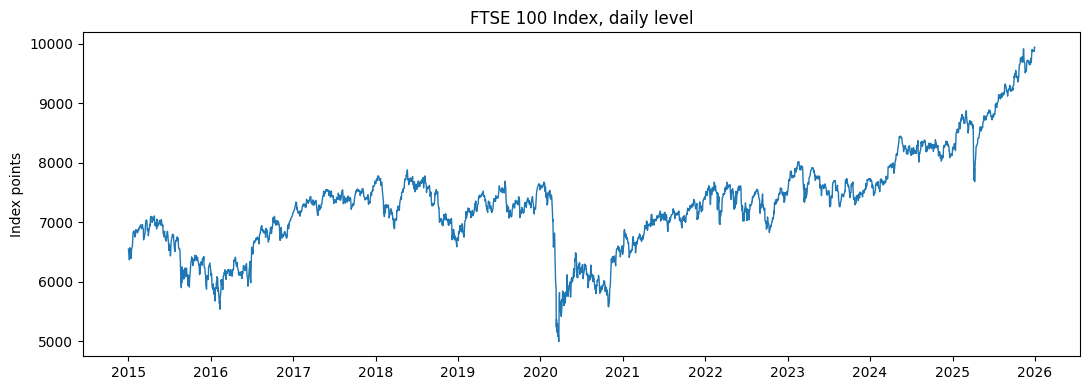

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(ftse.index, ftse["FTSE100"], lw=1)
ax.set_title("FTSE 100 Index, daily level")
ax.set_ylabel("Index points")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

## Step 5: Daily log returns (%)

$$r_t = 100 \times \ln\left(\frac{P_t}{P_{t-1}}\right)$$

As in the interval estimation tutorial, we test the mean of **returns**, not prices.

In [5]:
ftse["Return"] = np.log(ftse["FTSE100"]).diff() * 100   # log return, in %
returns = ftse["Return"].dropna()                        # first day has no return → drop it

returns.head(10)     # first 10 daily returns, with their dates

Date
2015-01-05   -2.014717
2015-01-06   -0.793205
2015-01-07    0.833707
2015-01-08    2.312690
2015-01-09   -1.054242
2015-01-12    0.004611
2015-01-13    0.625601
2015-01-14   -2.377403
2015-01-15    1.711801
2015-01-16    0.789331
Name: Return, dtype: float64

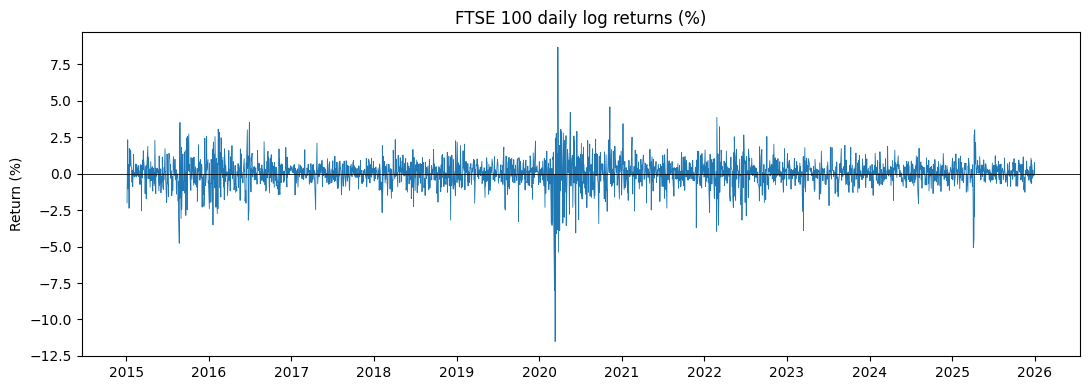

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(returns.index, returns, lw=0.6)
ax.axhline(0, color="black", lw=0.6)                     # line at zero: the value in H₀
ax.set_title("FTSE 100 daily log returns (%)")
ax.set_ylabel("Return (%)")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

## Step 6: Sample statistics

In [7]:
n    = len(returns)               # sample size: number of daily returns
xbar = returns.mean()             # sample mean x̄
s    = returns.std(ddof=1)        # sample standard deviation s (estimate of σ)
se   = s / np.sqrt(n)             # standard error of the mean = s / √n

print(f"n              = {n}")
print(f"Mean (x̄)       = {xbar:.4f}%")
print(f"Std dev (s)    = {s:.4f}%")
print(f"Standard error = {se:.4f}%")

n              = 2777
Mean (x̄)       = 0.0150%
Std dev (s)    = 0.9739%
Standard error = 0.0185%


# Hypothesis Testing: p-value Approach

## Step 7: State the hypotheses

We run two tests at the **5% significance level (α = 0.05)**.

### Test 1
**Statement:** An analyst claims that the average daily return of the FTSE 100 is **different from zero**.

**Hypotheses:**
* **H₀: μ = 0** (the average daily return is zero)
* **H₁: μ ≠ 0** (the average daily return is not zero)

**Type of test: two-tailed.** H₁ uses "≠", so the mean could be above **or** below zero.
We look for evidence in **both tails** of the distribution.

### Test 2
**Statement:** An investor claims that the average daily return of the FTSE 100 is **greater than zero**, meaning the index earns a positive return on average.

**Hypotheses:**
* **H₀: μ ≤ 0** (the average daily return is zero or negative)
* **H₁: μ > 0** (the average daily return is positive)

**Type of test: one-tailed (right-tailed).** H₁ uses ">", so we only look for evidence in **one direction**, the **right tail**.

### Decision rule
Reject H₀ if the **p-value < 0.05**.

> **Tip:** the claim you want to find evidence for always goes in **H₁**.
> The sign in H₁ tells you the type of test: **≠ → two-tailed**, **> → right-tailed**, **< → left-tailed**.

## Step 8: Two-tailed test

In [8]:
alpha = 0.05

result_two_tail = stats.ttest_1samp(returns, popmean=0)     # H₁: μ ≠ 0

print(f"t statistic = {result_two_tail.statistic:.4f}")
print(f"p-value     = {result_two_tail.pvalue:.4f}")

if result_two_tail.pvalue < alpha:
    print("Decision: reject H₀")
else:
    print("Decision: do not reject H₀")

t statistic = 0.8117
p-value     = 0.4170
Decision: do not reject H₀


**Interpretation:** the p-value (0.417) is greater than 0.05, so we **do not reject H₀**.
There is no evidence that the average daily return of the FTSE 100 is different from zero.

This does **not** prove the mean is exactly zero. Daily returns are very noisy (SD ≈ 0.97%)
compared with their small average (≈ 0.015%), so a real but small mean is hard to detect.

## Step 9: One-tailed test

In [9]:
result_one_tail = stats.ttest_1samp(returns, popmean=0, alternative="greater")   # H₁: μ > 0

print(f"t statistic = {result_one_tail.statistic:.4f}")
print(f"p-value     = {result_one_tail.pvalue:.4f}")

if result_one_tail.pvalue < alpha:
    print("Decision: reject H₀")
else:
    print("Decision: do not reject H₀")

t statistic = 0.8117
p-value     = 0.2085
Decision: do not reject H₀


**Interpretation:** the p-value (0.209) is greater than 0.05, so we **do not reject H₀**.
There is no evidence that the average daily return of the FTSE 100 is greater than zero.

Notice that the one-tailed p-value is **half** [](http://)the two-tailed p-value, because we only look at one tail.[](http://)

## Step 10: Hypothesis Testing: Critical Value Approach through Visualisation

* The **red areas** are the **rejection regions** (α = 5%).
* The **blue dashed line** is our t statistic.
* **If the blue line falls inside a red area, we reject H₀.**

**Plot: the critical value approach**-Two Tail Test

The **critical value** is the cut-off point. For a two-tailed test at α = 0.05 it is **±1.96**.
* The **red areas** beyond the critical values are the **rejection regions** (2.5% in each tail).
* The **blue line** is our t statistic.
* **Decision rule:** if the blue line is inside a red area, we reject H₀.

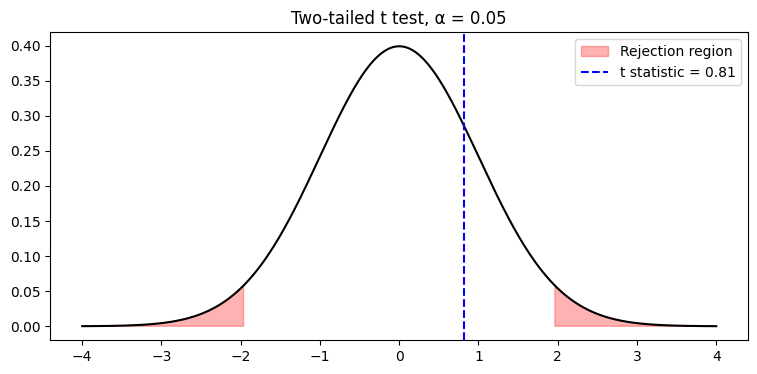

In [11]:
t_stat = result_two_tail.statistic
x = np.linspace(-4, 4, 500)
y = stats.t.pdf(x, n - 1)
t_crit = stats.t.ppf(1 - alpha/2, n - 1)     # two-tailed critical value

plt.figure(figsize=(9, 4))
plt.plot(x, y, color="black")
plt.fill_between(x, y, where=(abs(x) >= t_crit), color="red", alpha=0.3, label="Rejection region")
plt.axvline(t_stat, color="blue", ls="--", label=f"t statistic = {t_stat:.2f}")
plt.title("Two-tailed t test, α = 0.05")
plt.legend()
plt.show()

Our t statistic (0.81) is between −1.96 and +1.96, so it is **not** in a red area. We **do not reject H₀**.

This matches the p-value approach (p = 0.417 > 0.05). **Both approaches always give the same decision.**

**Plot: the critical value approach**-One Tail Test

For a one-tailed (right-tailed) test at α = 0.05, the critical value is **1.65**.
All 5% of the rejection region is in the **right tail**.

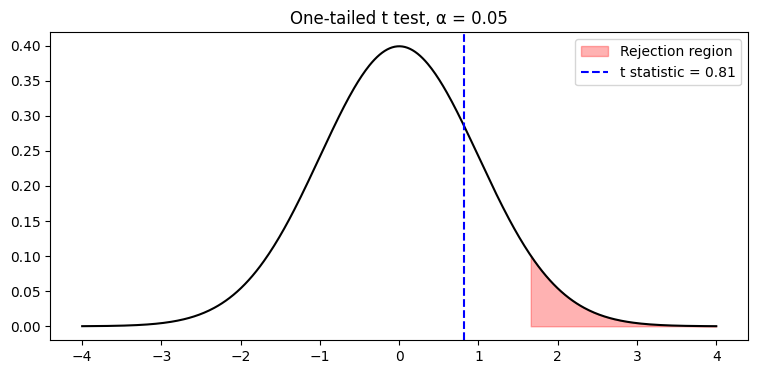

In [14]:
t_crit_one = stats.t.ppf(1 - alpha, n - 1)   # one-tailed critical value

plt.figure(figsize=(9, 4))
plt.plot(x, y, color="black")
plt.fill_between(x, y, where=(x >= t_crit_one), color="red", alpha=0.3, label="Rejection region")
plt.axvline(t_stat, color="blue", ls="--", label=f"t statistic = {t_stat:.2f}")
plt.title("One-tailed t test, α = 0.05")
plt.legend()
plt.show()

Our t statistic (0.81) is less than 1.65, so it is **not** in the red area. We **do not reject H₀**.

This matches the p-value approach (p = 0.209 > 0.05).

**Interpretation:**
* **Two-tailed test:** the rejection regions are in **both tails** (beyond ±1.96). Our t statistic (0.81) is **not** in a red area.
* **One-tailed test:** the rejection region is only in the **right tail** (beyond 1.65). Our t statistic (0.81) is **not** in the red area.

In both tests the blue line is outside the rejection region, so we **do not reject H₀**.
This matches the p-values (0.417 and 0.209), which are both greater than 0.05.

## Step 11: Two-sample test: BP vs Shell

BP and Shell are both UK energy companies. Did they have the same average daily return?

* **H₀: μ_BP = μ_SHEL**
* **H₁: μ_BP ≠ μ_SHEL**

Both shares trade on the same days and react to the same oil news, so we use a **paired t test**.

In [12]:
pair = equities[["BP", "SHEL"]].dropna()                   # days when both traded
pair_returns = (np.log(pair).diff() * 100).dropna()         # daily log returns (%)

print(f"BP mean   = {pair_returns['BP'].mean():.4f}%")
print(f"SHEL mean = {pair_returns['SHEL'].mean():.4f}%")

result_pair = stats.ttest_rel(pair_returns["BP"], pair_returns["SHEL"])   # paired t test
print(f"\nt statistic = {result_pair.statistic:.4f}")
print(f"p-value     = {result_pair.pvalue:.4f}")

if result_pair.pvalue < alpha:
    print("Decision: reject H₀")
else:
    print("Decision: do not reject H₀")

BP mean   = 0.0021%
SHEL mean = 0.0086%

t statistic = -0.3601
p-value     = 0.7188
Decision: do not reject H₀


**Interpretation:** the p-value (0.719) is greater than 0.05, so we **do not reject H₀**.

**But the sample means are different, so why?** H₀ is about the **true** (population) means, not our sample.
The gap between BP and Shell is only **0.0065% a day**, while daily returns vary by about **1.9% a day**.
A gap this small could easily happen by chance even if the true means were equal (t = −0.36).
So we have **no evidence** that BP and Shell have different average daily returns.

**Why a paired t test?** BP and Shell are observed on the **same days** and react to the same oil news,
so the two samples are **not independent**. The paired test works on the **daily difference**
(BP return − Shell return), which compares the two shares day by day.